# Quick test

https://pypi.org/project/foundry-local-sdk/

In [1]:
#pip install foundry-local-sdk

In [2]:
import matplotlib.pyplot as plt
import os
import openai
import numpy as np
import pandas as pd
import requests
import sys
import time

from foundry_local_sdk import Configuration, FoundryLocalManager

In [3]:
sys.version

'3.12.12 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 20:05:38) [MSC v.1929 64 bit (AMD64)]'

In [4]:
%pip show foundry-local-sdk

Name: foundry-local-sdk
Version: 2.2.1
Summary: Foundry Local Python SDK (v2): in-process Python bindings for the Foundry Local native runtime.
Home-page: https://github.com/microsoft/Foundry-Local
Author: 
Author-email: Microsoft Corporation <foundrylocaldevs@microsoft.com>
License-Expression: MIT
Location: C:\Users\seretkow\AppData\Local\anaconda3\envs\foundry\Lib\site-packages
Requires: cffi, onnxruntime, onnxruntime-genai-core, openai, pydantic, requests, typing_extensions
Required-by: 
Note: you may need to restart the kernel to use updated packages.


## Foundry Local manager 

In [5]:
FoundryLocalManager.initialize(Configuration(app_name="quick_chat_test"))
manager = FoundryLocalManager.instance

In [6]:
models = manager.catalog.list_models()

df = pd.DataFrame(
    [
        {
            "alias": m.alias,
            "id": m.id,
            "cached": m.is_cached,
            "loaded": m.is_loaded,
            "context_length": m.context_length,
            "input": m.input_modalities,
            "capabilities": m.capabilities,
            "tool_calling": m.supports_tool_calling,
        }
        for m in models
    ]
).sort_values("alias").reset_index(drop=True)

print(f"{len(df)} models in catalog")
df

56 models in catalog


,alias,id,cached,loaded,context_length,input,capabilities,tool_calling
0,deepseek-r1-1.5b,deepseek-r1-distill-qwen-1.5b-generic-cpu:4,False,False,None,text,None,None
1,deepseek-r1-14b,deepseek-r1-distill-qwen-14b-generic-cpu:4,False,False,None,text,None,None
2,deepseek-r1-7b,deepseek-r1-distill-qwen-7b-generic-cpu:4,False,False,None,text,None,None
3,deepseek-r1-8b,deepseek-r1-distill-llama-8b-generic-cpu:4,False,False,None,text,None,None
4,gemma-4-e2b-it,gemma-4-e2b-it-generic-cpu:3,False,False,None,"text,image,audio",None,True
5,gpt-oss-20b,gpt-oss-20b-generic-cpu:1,True,False,None,text,None,None
6,ministral-3-3b-instruct-2512,ministral-3-3b-instruct-2512-generic-cpu:2,False,False,None,"text,image",None,True
7,mistral-7b-v0.2,mistralai-Mistral-7B-Instruct-v0-2-generic-cpu:3,True,False,None,text,None,None
8,mistral-nemo-12b-instruct,mistral-nemo-12b-instruct-generic-cpu:1,False,False,None,text,None,True
9,nemotron-3.5-asr-streaming-0.6b,nemotron-3.5-asr-streaming-0.6b-generic-cpu:3,False,False,None,audio,None,None


In [7]:
df['input'].value_counts(sort=True)

input
text                38
audio                9
text,image           8
text,image,audio     1
Name: count, dtype: int64

In [8]:
df['tool_calling'].value_counts(sort=True)

tool_calling
True     32
False     2
Name: count, dtype: int64

In [9]:
df[df["cached"] == True]

,alias,id,cached,loaded,context_length,input,capabilities,tool_calling
5,gpt-oss-20b,gpt-oss-20b-generic-cpu:1,True,False,None,text,None,None
7,mistral-7b-v0.2,mistralai-Mistral-7B-Instruct-v0-2-generic-cpu:3,True,False,None,text,None,None
22,qwen2.5-0.5b,qwen2.5-0.5b-instruct-generic-cpu:4,True,False,None,text,None,True


In [10]:
df[df["loaded"] == True]

,alias,id,cached,loaded,context_length,input,capabilities,tool_calling


In [11]:
df['alias'].value_counts(sort=True)

alias
deepseek-r1-1.5b                        1
deepseek-r1-14b                         1
deepseek-r1-7b                          1
deepseek-r1-8b                          1
gemma-4-e2b-it                          1
gpt-oss-20b                             1
ministral-3-3b-instruct-2512            1
mistral-7b-v0.2                         1
mistral-nemo-12b-instruct               1
nemotron-3.5-asr-streaming-0.6b         1
nemotron-speech-streaming-en-0.6b       1
nemotron-speech-streaming-es-0.6b       1
olmo-3-7b-instruct                      1
parakeet-tdt-0.6b-v2                    1
phi-3-mini-128k                         1
phi-3-mini-4k                           1
phi-3.5-mini                            1
phi-4                                   1
phi-4-mini                              1
phi-4-mini-instruct-generic-cpu-dq44    1
phi-4-mini-reasoning                    1
phi-4-reasoning                         1
qwen2.5-0.5b                            1
qwen2.5-1.5b                

In [12]:
if not manager.urls:
    manager.start_web_service()

base: str = manager.urls[0]
print(manager.urls)

['http://127.0.0.1:64349']


In [13]:
print(f"Bound URLs: {manager.urls}")

for m in manager.catalog.get_loaded_models():
    print(f"loaded: {m.id}  ctx={m.context_length}  tools={m.supports_tool_calling}")

for ep in manager.discover_eps():
    print(f"EP {ep.name}: registered={ep.is_registered}")

Bound URLs: ['http://127.0.0.1:64349']
EP OpenVINOExecutionProvider: registered=False
EP CUDAExecutionProvider: registered=False
EP WebGpuExecutionProvider: registered=False


In [14]:
MODEL_ALIAS = "qwen2.5-0.5b"

In [15]:
model = manager.catalog.get_model(MODEL_ALIAS)

if not model.is_cached:
    model.download(lambda pct: print(
        f"\rDownloading {MODEL_ALIAS}: {pct:5.2f}%", end="", flush=True))
    print()

model.load()
print(f"Model loaded: {model.id}")

Model loaded: qwen2.5-0.5b-instruct-generic-cpu:4


In [16]:
PROMPT = "Hello"

In [17]:
base_url: str = f"{manager.urls[0]}/v1"
client = openai.OpenAI(base_url=base_url, api_key="notneeded")

In [18]:
start = time.perf_counter()
stream = client.chat.completions.create(
    model=model.id,
    messages=[{
        "role": "user",
        "content": PROMPT
    }],
    stream=True,
)

for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        print(chunk.choices[0].delta.content, end="", flush=True)

print(f"\n\nDone in {time.perf_counter() - start:.3f}s")

Hello! How may I assist you today?

Done in 0.369s


In [19]:
N_RUNS = 100
records = []

for i in range(1, N_RUNS + 1):
    start = time.perf_counter()
    ttft = None
    n_chunks = 0
    error = None

    try:
        stream = client.chat.completions.create(
            model=model.id,
            messages=[{"role": "user", "content": PROMPT}],
            stream=True,
        )

        for chunk in stream:
            if chunk.choices and chunk.choices[0].delta.content:
                if ttft is None:
                    ttft = time.perf_counter() - start
                n_chunks += 1
    except Exception as exc:
        error = f"{type(exc).__name__}: {exc}"

    total = time.perf_counter() - start
    records.append(
        {
            "run": i,
            "total_s": total,
            "ttft_s": ttft,
            "n_chunks": n_chunks,
            "error": error,
        }
    )
    print(f"[{i:>3}/{N_RUNS}] Elapsed time = {total:.3f}s TTFT = {ttft or float('nan'):.3f}s {error or ''}")

df = pd.DataFrame(records)
ok = df[df["error"].isna()]

print(f"\nOK: {len(ok)} | Errors: {df['error'].notna().sum()}")

[  1/100] Elapsed time = 0.345s TTFT = 0.162s 
[  2/100] Elapsed time = 0.369s TTFT = 0.194s 
[  3/100] Elapsed time = 1.165s TTFT = 0.179s 
[  4/100] Elapsed time = 0.365s TTFT = 0.195s 
[  5/100] Elapsed time = 1.009s TTFT = 0.179s 
[  6/100] Elapsed time = 0.390s TTFT = 0.213s 
[  7/100] Elapsed time = 0.637s TTFT = 0.197s 
[  8/100] Elapsed time = 0.359s TTFT = 0.188s 
[  9/100] Elapsed time = 0.368s TTFT = 0.201s 
[ 10/100] Elapsed time = 0.593s TTFT = 0.182s 
[ 11/100] Elapsed time = 0.355s TTFT = 0.194s 
[ 12/100] Elapsed time = 0.345s TTFT = 0.178s 
[ 13/100] Elapsed time = 0.580s TTFT = 0.171s 
[ 14/100] Elapsed time = 0.608s TTFT = 0.180s 
[ 15/100] Elapsed time = 0.344s TTFT = 0.176s 
[ 16/100] Elapsed time = 0.349s TTFT = 0.182s 
[ 17/100] Elapsed time = 0.364s TTFT = 0.182s 
[ 18/100] Elapsed time = 0.368s TTFT = 0.196s 
[ 19/100] Elapsed time = 0.371s TTFT = 0.194s 
[ 20/100] Elapsed time = 1.174s TTFT = 0.226s 
[ 21/100] Elapsed time = 0.658s TTFT = 0.227s 
[ 22/100] Ela

In [20]:
df

,run,total_s,ttft_s,n_chunks,error
0,1,0.345247,0.162194,9,None
1,2,0.368780,0.193731,9,None
2,3,1.165168,0.179206,54,None
3,4,0.365032,0.195074,9,None
4,5,1.009225,0.178790,49,None
...,...,...,...,...,...
95,96,0.364885,0.186647,9,None
96,97,0.364399,0.191224,9,None
97,98,0.363404,0.188693,9,None
98,99,0.350182,0.185823,9,None


In [21]:
df.describe()

,run,total_s,ttft_s,n_chunks
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,0.542389,0.198917,18.060000
std,29.011492,0.291885,0.027053,15.246672
min,1.000000,0.336054,0.162194,9.000000
25%,25.750000,0.356173,0.181986,9.000000
50%,50.500000,0.375078,0.192758,9.000000
75%,75.250000,0.648118,0.205944,24.250000
max,100.000000,1.397169,0.365277,62.000000


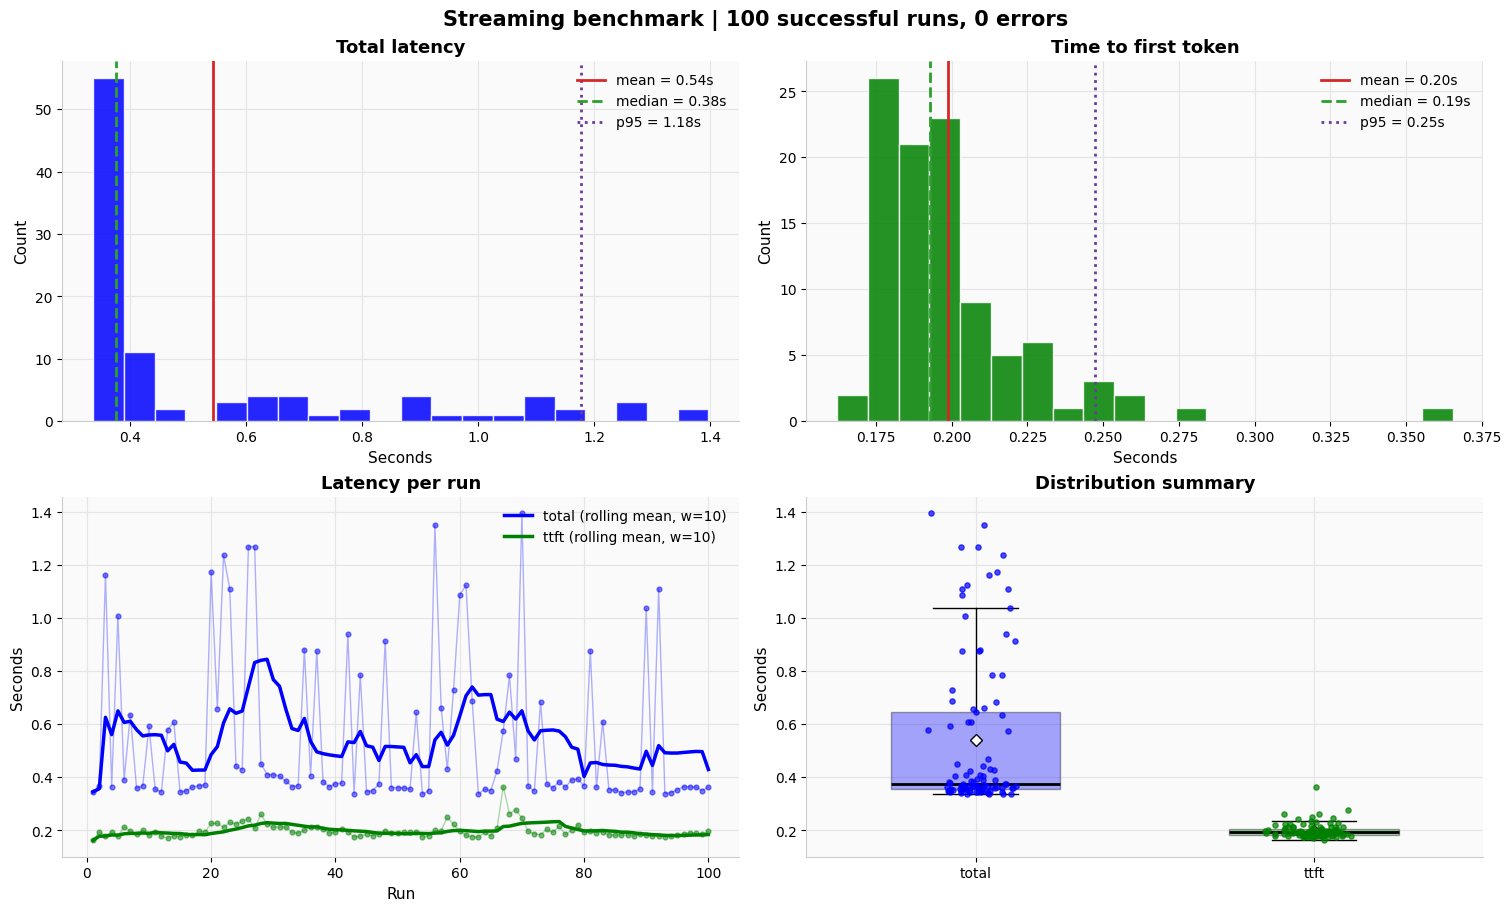

In [22]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#fafafa",
        "axes.edgecolor": "#cccccc",
        "axes.grid": True,
        "grid.color": "#e5e5e5",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "legend.frameon": False,
        "font.size": 10,
    }
)

C_TOTAL = "blue"
C_TTFT = "green"
WINDOW = 10

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)

# 1 and 2. Distributions with mean / median / p95 markers
series = [
    ("Total latency", ok["total_s"].dropna(), C_TOTAL, axes[0, 0]),
    ("Time to first token", ok["ttft_s"].dropna(), C_TTFT, axes[0, 1]),
]
for title, values, color, ax in series:
    ax.hist(values, bins=20, color=color, alpha=0.85, edgecolor="white")
    stats = [
        ("mean", values.mean(), "-", "#d62728"),
        ("median", values.median(), "--", "#2ca02c"),
        ("p95", values.quantile(0.95), ":", "#6a3d9a"),
    ]
    for name, val, ls, c in stats:
        ax.axvline(val, color=c, linestyle=ls, linewidth=2, label=f"{name} = {val:.2f}s")
    ax.set_title(title)
    ax.set_xlabel("Seconds")
    ax.set_ylabel("Count")
    ax.legend(loc="upper right")

# 3. Per-run latency with rolling mean and error markers
ax = axes[1, 0]
for col, color, label in [("total_s", C_TOTAL, "total"), ("ttft_s", C_TTFT, "ttft")]:
    ax.plot(ok["run"], ok[col], color=color, alpha=0.3, linewidth=1)
    ax.scatter(ok["run"], ok[col], color=color, s=12, alpha=0.5)
    rolling = ok.set_index("run")[col].rolling(WINDOW, min_periods=1).mean()
    ax.plot(rolling.index, rolling.values, color=color, linewidth=2.5, label=f"{label} (rolling mean, w={WINDOW})")

err = df[df["error"].notna()]
if not err.empty:
    ax.scatter(err["run"], np.zeros(len(err)), marker="x", color="crimson", s=50, label="error", zorder=5)

ax.set_title("Latency per run")
ax.set_xlabel("Run")
ax.set_ylabel("Seconds")
ax.legend(loc="upper right")

# 4. Boxplot with individual points
ax = axes[1, 1]
data = [ok["total_s"].dropna(), ok["ttft_s"].dropna()]
bp = ax.boxplot(
    data,
    tick_labels=["total", "ttft"],
    showmeans=True,
    patch_artist=True,
    widths=0.5,
    showfliers=False,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
    medianprops={"color": "black", "linewidth": 2},
)
for patch, color in zip(bp["boxes"], [C_TOTAL, C_TTFT]):
    patch.set_facecolor(color)
    patch.set_alpha(0.35)

rng = np.random.default_rng(0)
for idx, (values, color) in enumerate(zip(data, [C_TOTAL, C_TTFT]), start=1):
    ax.scatter(idx + rng.normal(0, 0.06, len(values)), values, color=color, s=14, alpha=0.7, zorder=3)

ax.set_title("Distribution summary")
ax.set_ylabel("Seconds")

fig.suptitle(
    f"Streaming benchmark | {len(ok)} successful runs, {len(err)} errors",
    fontsize=15,
    fontweight="bold",
)

plt.show()